In [72]:
# %%
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib as mpl


In [73]:
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIX Two Text", "STIXGeneral"],
    "mathtext.fontset": "stix",

    "font.size": 26,
    "axes.labelsize": 28,
    "xtick.labelsize": 24,
    "ytick.labelsize": 24,
    "legend.fontsize": 22,

    "axes.linewidth": 1.2,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
})

In [ ]:
# Source - https://stackoverflow.com/a/71692086
# Posted by Gabriele
# Retrieved 2026-06-30, License - CC BY-SA 4.0

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"]

# %%
e = np.e 
pi=np.pi
KA = 0.001
alpha0_set = np.linspace(0.5, 1, 6) * np.pi
phi_set = np.array([pi/6, pi/12])
u1 =0.3;
u2 =2
r = np.sqrt(np.cosh(u1)/np.cosh(u2))




# %%
# Initialize a list to accumulate dataframes from all files
all_data = pd.read_csv("./ellipse_defects_data.csv")
print(list(all_data))
all_data=all_data[all_data['max_delta']>=10]
all_data=all_data[all_data['min_delta']<=-10]
all_data = all_data[all_data['t']>0]

math_data = pd.read_csv('../fig7data_mathematica.csv')
l_array = np.array(math_data['l'])
phi_array = np.array(math_data['phi'])
f_array = np.array(math_data['f']) # f=1-log(r)/log(rho) from mathematica
color_array= ['tab:blue', 'tab:orange', 'teal', 'xkcd:magenta', 'tab:brown', 'cyan']


ru_set = (np.unique(all_data['r_param']))
l = len(ru_set)
print(ru_set)

['alpha0', 'phi_param', 'r_param', 'KA', 't', 'max_x', 'max_y', 'min_x', 'min_y', 'r_max', 'r_min', 'phi_max', 'phi_min', 'max_delta', 'min_delta', 'total_free_energy']
[0.52711793]


In [75]:
all_data['total_free_energy']/=4
all_data['dphi']= all_data['phi_max']-all_data['phi_min']

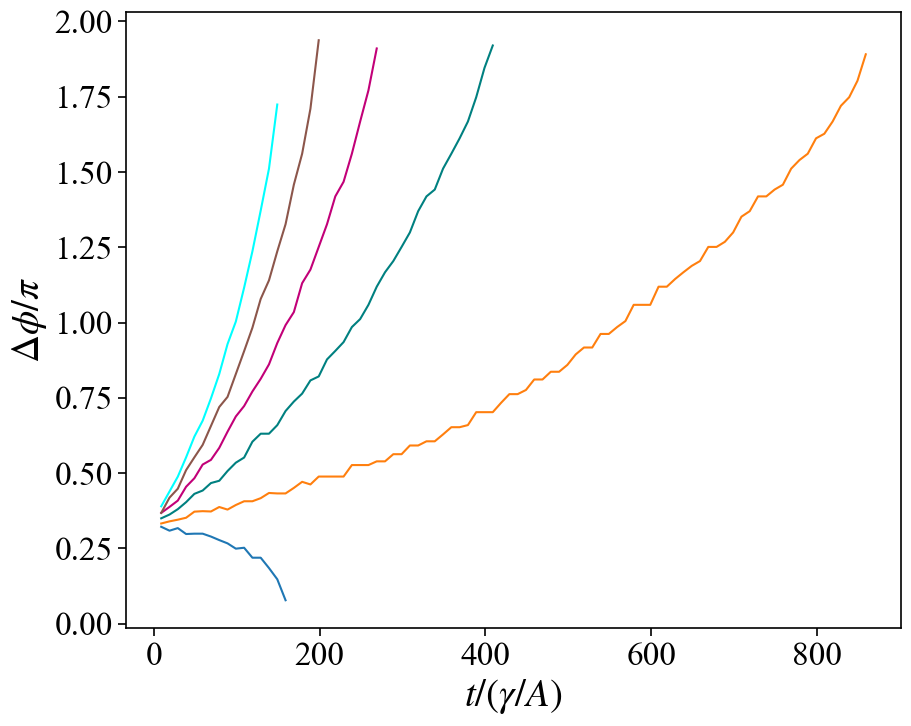

In [88]:
for phi in phi_set[:-1]:
        fig, axs = plt.subplots(1, 1, figsize=(10, 8), sharex=False)
        for i, alpha0 in np.ndenumerate(alpha0_set[:]):
            data = all_data[np.isclose(all_data['alpha0'], alpha0) & np.isclose(all_data['phi_param'], phi)&  np.isclose(all_data['r_param'], r)]
            # data=data[::2]
            # axs[0].scatter( data['phi_max'], data['total_free_energy'],s=1, label = "$\\alpha_0$ = {0:.2f}".format(alpha0))
            axs.plot(data['t'], (data['phi_max']-data['phi_min'])/pi, label = "$\\alpha_0$ = {0:.2f}$\\pi$".format(alpha0/pi), color = color_array[i[0]])
        # axs.set_title("$u_1={0:.2f}, u_2= {1:.2f}$, $\\Delta\\phi_0$={2:.2f}$\\pi$".format(u1, u2, 2*phi/pi))
        # axs[0].set_xlabel("$\\phi (\\delta_{max})$")
        axs.set_ylabel("$\\Delta\\phi/\\pi$")
        # axs[1].set_ylabel("$F$")
        axs.set_xlabel("$t/(\\gamma/A)$")
        # axs.legend()
        plt.savefig('./ellipse_dphi_time.pdf', dpi =300)